# Entrega 1: Priorizar el despacho de una cuadrilla

**Machine Learning** · Grupos de 4 · 10 % de la calificación final · Vence el **martes 6 de octubre**

**Integrantes**

1. Marcos Devincenzi
2. Facundo Díaz
3. Santiago Alba
4. Domingo Leiva

---

La consigna completa está en `enunciado.pdf`. Este notebook fija **las trece secciones y su orden**; la corrección se hace **contra el enunciado**, no contra el template.

Condiciones de uso:

- Las celdas de texto describen qué se pide en cada sección y **no se eliminan**. Las respuestas escritas se agregan en las celdas marcadas para eso, que pueden extenderse tanto como haga falta.
- Las celdas de código llegan vacías y pueden dividirse en tantas como convenga.
- **El notebook se entrega ejecutado de punta a punta**, con todas las salidas visibles y en el orden en que se generaron. Un notebook sin ejecutar no está entregado.
- Toda celda con aleatoriedad fija su semilla, y la semilla se mantiene igual en todas las comparaciones del notebook: dos resultados que se comparan no pueden diferir por la partición.

**Los datos se construyen uniendo dos fuentes**, y esa construcción es parte del trabajo:

1. El archivo abierto de OSE «Solicitudes y reclamos operativos 2024», que se descarga de <https://datos.ose.com.uy/dataset/reclamos-operativos>. Es un ZIP de unos 10 MB que descomprime a un CSV de unos 114 MB **separado por punto y coma**.
2. `data/entregas_reclamos_complemento.csv`, que aporta la cátedra.

La ruta del archivo descargado se declara **en la celda de configuración de abajo y en ningún otro lado**, de modo que el notebook pueda reproducirse cambiando una sola línea. En Colab, los dos archivos deben subirse o montarse antes de la primera lectura.

### Configuración: importaciones, rutas y semilla

Importar las bibliotecas que el trabajo use, declarar las rutas de los dos archivos y fijar la semilla. Nada de esta celda se evalúa.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_squared_error, precision_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import GridSearchCV, KFold, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text

warnings.filterwarnings("ignore", message="Found unknown categories")  # una categoría con un solo reclamo
plt.rcParams.update({"figure.figsize": (8, 3.6), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

# Rutas de los archivos: se declaran acá y en ningún otro lado
ARCHIVO_OSE = Path("data/solicitudes_reclamos_operativos_2024.csv")
ARCHIVO_COMPLEMENTO = Path("data/entregas_reclamos_complemento.csv")
ARCHIVO_METADATOS = Path("data/metadatos_ose.csv")

SEMILLA = 42
PLAZO_HORAS = 72
COSTO_FP = 45          # USD: priorizar un reclamo que no iba a superar el plazo
COSTO_FN = 270         # USD: no priorizar un reclamo que sí lo supera
VOLUMEN_ANUAL = 390_000

print("Entorno listo.")

Entorno listo.


## 1. Ingesta, unión y auditoría del conjunto

**Primero, la construcción de la tabla de trabajo.** Documentar cuántas filas trae cada fuente, cuántas sobreviven al filtro, cuántas quedan después de la unión y **qué garantiza que la unión no perdió ni multiplicó registros**. Una unión que cambia el número de filas sin explicación es un error de la sección, no un detalle.

**Después, la auditoría**, antes de ajustar ningún modelo: dimensiones, tipos, resumen descriptivo, distribución de cada variable, valores faltantes por columna y el patrón que siguen, filas repetidas, valores imposibles y cardinalidad de las variables categóricas.

Para **cada** variable con faltantes, diagnosticar el mecanismo —MCAR, MAR o MNAR— y sostener el diagnóstico con el contraste que lo separa de las otras dos alternativas. Cuando el mecanismo no sea diagnosticable con los datos observados, decirlo y explicar por qué. **El tratamiento se deriva del diagnóstico, no al revés.**

**Por último, construir la respuesta binaria** a partir del plazo comprometido, dejando dicho qué se hizo con los registros para los que esa construcción no tiene sentido.

Un hallazgo sin la cifra o el gráfico que lo produce no cuenta como hallazgo.

In [2]:
ose = pd.read_csv(ARCHIVO_OSE, sep=";", encoding="utf-8-sig", dtype={"id_reclamo_operativo_m": str})
complemento = pd.read_csv(ARCHIVO_COMPLEMENTO, dtype={"id_reclamo": str})
metadatos = pd.read_csv(ARCHIVO_METADATOS, sep=";", encoding="cp1252")

print("Diccionario de OSE (metadatos):")
for nombre, descripcion in zip(metadatos["nombre_de_atributo"], metadatos["descripcion"]):
    print(f"  {nombre:26s} {descripcion}")

print(f"\nArchivo de OSE: {len(ose)} filas")
print(f"Complemento:    {len(complemento)} filas")

# Filtrar OSE a los reclamos del complemento y unir por el identificador
filtrado = ose[ose["id_reclamo_operativo_m"].isin(complemento["id_reclamo"])]
tabla = complemento.merge(filtrado, left_on="id_reclamo", right_on="id_reclamo_operativo_m",
                          how="inner", validate="one_to_one")
print(f"OSE filtrado:   {len(filtrado)} filas")
print(f"Tras la unión:  {len(tabla)} filas")

# VERIFICACIÓN: la unión no perdió ni multiplicó reclamos
assert ose["id_reclamo_operativo_m"].is_unique, "hay identificadores repetidos en OSE"
assert complemento["id_reclamo"].is_unique, "hay identificadores repetidos en el complemento"
assert len(filtrado) == len(complemento), "algún reclamo del complemento no está en OSE"
assert len(tabla) == len(complemento), "la unión cambió el número de filas"
print("\nLa unión conserva exactamente los reclamos del complemento, sin perder ni duplicar.")

tabla = tabla.drop(columns="id_reclamo_operativo_m")

Diccionario de OSE (metadatos):
  region                     Región OSE a la que pertenece el departamento.
  departamento               Departamento al que pertenece el reclamo o solicitud operativa.
  fecha_ingreso              Fecha de ingreso de la solicitud o reclamo operativo.
  id_ro_m                    Identificador de la solicitud o reclamo pseudonimizado. El identificador original fue reemplazado por un valor hash irreversible.
  tipo_ro                    Clasificación del reclamo operativo. (ej:'Medidor Hurtado')."
  tipo_complejidad           Clasificación  que refiere a la complejidad para el equipo que resuelve (ej:"'Con corte de pavimento', etc)."
  ausencia_agua              Indica si se reclama por ausencia de agua.
  baja_presion               Indica si se reclama por baja presión.
  inunda                     Indica si se reclama con inundación.
  fecha_resuelto_visita      Fecha de la ultima visita que resolvió el reclamo si el reclamo tuvo una orden de trabajo as

Dimensiones: 3964 filas x 21 columnas

Tipos de cada columna:
id_reclamo                       str
distancia_centro_km          float64
conexiones_afectadas         float64
calificacion_atencion        float64
año                            int64
region                           str
departamento                     str
fecha_ingreso                    str
id_tipo_reclamo_operativo        str
tipo_complejidad                 str
ausencia_agua                    str
baja_presion                     str
inunda                           str
fecha_resuelto_visita            str
fecha_resuelto_sistema           str
tiempo_resolucion_minutos      int64
id_centro_tecnico              int64
estado_resuelto                  str
tipo_orden                       str
grupo_orden                      str
fecha_foto                       str

Resumen de las numéricas:
                            count     mean        std        min      25%      50%      75%       max
distancia_centro_km        3964.

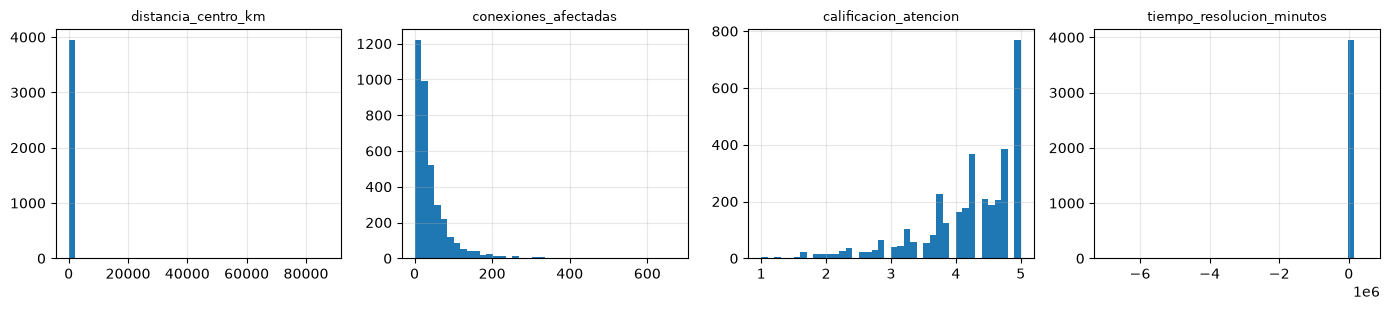


region:
region
MDEO             1740
CENTRO            837
LITORAL NORTE     354
LITORAL SUR       292
UGD               288
NORESTE           278
SURESTE           175

departamento:
departamento
MONTEVIDEO        1740
CANELONES          680
MALDONADO          288
SALTO              149
SAN JOSE           111
COLONIA            110
RIVERA             109
ROCHA               99
PAYSANDU            99
TACUAREMBO          98
FLORIDA             81
DURAZNO             76
ARTIGAS             74
CERRO LARGO         71
SORIANO             54
LAVALLEJA           42
TREINTA Y TRES      34
RIO NEGRO           32
FLORES              17

id_tipo_reclamo_operativo:
id_tipo_reclamo_operativo
 RP  Denuncia de Pérdida                                          1714
 PA  Problema de Abastecimiento (falta de agua o poca presion)    1625
 RS  Saneamiento del Interior                                      239
 SV  Solicitudes Varias                                            168
 RS Reposición y Señalizaci

In [3]:
print(f"Dimensiones: {tabla.shape[0]} filas x {tabla.shape[1]} columnas\n")
print("Tipos de cada columna:")
print(tabla.dtypes.to_string())

print("\nResumen de las numéricas:")
print(tabla.describe().T.round(2))

print("\nFaltantes por columna:")
print(tabla.isna().sum().loc[lambda s: s > 0].to_string())

print("\nCardinalidad de las categóricas:")
print(tabla.select_dtypes(exclude="number").nunique().sort_values().to_string())

# Distribución de las numéricas
NUM_CRUDAS = ["distancia_centro_km", "conexiones_afectadas", "calificacion_atencion",
              "tiempo_resolucion_minutos"]
fig, ejes = plt.subplots(1, 4, figsize=(14, 3.2))
for eje, col in zip(ejes, NUM_CRUDAS):
    eje.hist(tabla[col].dropna(), bins=40)
    eje.set_title(col, fontsize=9)
plt.tight_layout()
plt.show()

# Distribución de las categóricas de baja cardinalidad
for col in ["region", "departamento", "id_tipo_reclamo_operativo", "tipo_complejidad",
            "ausencia_agua", "baja_presion", "inunda", "estado_resuelto", "grupo_orden"]:
    print(f"\n{col}:")
    print(tabla[col].value_counts().to_string())

# Años de las fechas: 1900 es el código de "sin fecha" de los metadatos
print()
for col in ["fecha_ingreso", "fecha_resuelto_visita", "fecha_resuelto_sistema"]:
    años = pd.to_datetime(tabla[col], format="%Y/%m/%d %H:%M").dt.year
    print(f"{col}: {años.value_counts().to_dict()}")

In [4]:
minutos = tabla["tiempo_resolucion_minutos"]
print(f"tiempo = -1 (código de 'sin dato'): {(minutos == -1).sum()}")
print(f"otros tiempos negativos (imposibles): {(minutos < -1).sum()}")
negativos_h = minutos[minutos < -1] / 60
print(f"   de esos, entre -24 h y 0: {(negativos_h > -24).sum()}  (mediana {negativos_h.median():.1f} h)")
print(f"tiempo = 0: {(minutos == 0).sum()}")
print(f"centro técnico = -1: {(tabla['id_centro_tecnico'] == -1).sum()}")
print(f"tipo_orden = 'SIN DATOS': {tabla['tipo_orden'].isin(['SIN DATOS', 'S/DATOS']).sum()}")

copias = tabla.drop(columns="id_reclamo").duplicated()
print(f"filas repetidas (idénticas salvo el id): {copias.sum()}")
print(f"regiones por departamento (máximo): {tabla.groupby('departamento')['region'].nunique().max()}")

# Distancias imposibles: Uruguay mide unos 600 km de punta a punta
grandes = tabla["distancia_centro_km"] > 1000
print(f"\ndistancias mayores a 1000 km: {grandes.sum()} (máximo {tabla['distancia_centro_km'].max():,.0f})")
mediana_depto = tabla[~grandes].groupby("departamento")["distancia_centro_km"].median()
revision = tabla.loc[grandes, ["departamento", "distancia_centro_km"]].copy()
revision["si_eran_metros_km"] = revision["distancia_centro_km"] / 1000
revision["mediana_del_depto_km"] = revision["departamento"].map(mediana_depto)
print(revision.round(2).to_string())

tiempo = -1 (código de 'sin dato'): 10
otros tiempos negativos (imposibles): 321
   de esos, entre -24 h y 0: 291  (mediana -2.4 h)
tiempo = 0: 3
centro técnico = -1: 319
tipo_orden = 'SIN DATOS': 319
filas repetidas (idénticas salvo el id): 32
regiones por departamento (máximo): 1

distancias mayores a 1000 km: 21 (máximo 87,510)
     departamento  distancia_centro_km  si_eran_metros_km  mediana_del_depto_km
4           SALTO              65360.0              65.36                 57.62
21     MONTEVIDEO               6620.0               6.62                  6.99
27       PAYSANDU              39800.0              39.80                 49.94
158    MONTEVIDEO               5130.0               5.13                  6.99
189     LAVALLEJA              49790.0              49.79                 56.91
198     CANELONES              53550.0              53.55                 51.84
406     CANELONES              71420.0              71.42                 51.84
534     CANELONES          

reclamos válidos: 3604  (se quitaron 32 copias y 331 tiempos negativos)
prevalencia de incumplimiento: 0.1609
prevalencia si los negativos se etiquetaran 0: 0.1479

tiempo de resolución: media 66.6 h · mediana 18.7 h · máximo 8,731 h · asimetría 16.48


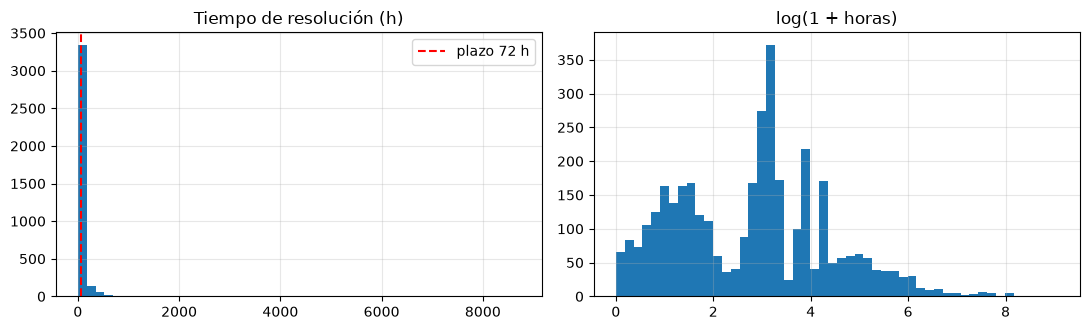

--- conexiones_afectadas: 231 faltantes (6.4 %)
    contra departamento               chi2 =   23.22   p = 0.1822
    contra id_tipo_reclamo_operativo  chi2 =   25.81   p = 0.0011
    contra tipo_complejidad           chi2 =    7.10   p = 0.1307
    contra ausencia_agua              chi2 =    5.85   p = 0.0156
    contra distancia_centro_km        mediana presente   27.8 · ausente   35.9   p = 0.0034
    contra tiempo_horas               mediana presente   18.4 · ausente   21.0   p = 0.0102
--- calificacion_atencion: 434 faltantes (12.0 %)
    contra departamento               chi2 =   20.13   p = 0.3254
    contra id_tipo_reclamo_operativo  chi2 =   23.77   p = 0.0025
    contra tipo_complejidad           chi2 =    4.42   p = 0.3516
    contra ausencia_agua              chi2 =   29.55   p = 0.0000
    contra distancia_centro_km        mediana presente   29.0 · ausente   26.9   p = 0.0153
    contra tiempo_horas               mediana presente   17.3 · ausente   49.7   p = 0.0000
--- id

In [5]:
datos = tabla.copy()

# 1. Códigos de "sin dato" de los metadatos -> faltante
for col in ["fecha_ingreso", "fecha_resuelto_visita", "fecha_resuelto_sistema"]:
    datos[col] = pd.to_datetime(datos[col], format="%Y/%m/%d %H:%M")
    datos.loc[datos[col].dt.year == 1900, col] = pd.NaT
datos["id_centro_tecnico"] = datos["id_centro_tecnico"].replace(-1, np.nan)
for col in ["estado_resuelto", "tipo_orden", "grupo_orden"]:
    datos[col] = datos[col].replace(["SIN DATOS", "S/DATOS"], np.nan)

# 2. Distancias cargadas en metros -> kilómetros
datos.loc[grandes, "distancia_centro_km"] = datos.loc[grandes, "distancia_centro_km"] / 1000

# 3. Copias exactas
datos = datos[~copias]

# 4. Respuesta en horas; los tiempos negativos no se pueden etiquetar y se excluyen
datos["tiempo_horas"] = datos["tiempo_resolucion_minutos"] / 60
datos = datos[datos["tiempo_horas"] >= 0].reset_index(drop=True)
datos["incumple"] = (datos["tiempo_horas"] > PLAZO_HORAS).astype(int)

print(f"reclamos válidos: {len(datos)}  (se quitaron {copias.sum()} copias y {(minutos < 0).sum()} tiempos negativos)")
print(f"prevalencia de incumplimiento: {datos['incumple'].mean():.4f}")

# Sensibilidad: qué prevalencia habría si los negativos contaran como "no incumple"
alternativa = minutos[~copias & (minutos != -1)].clip(lower=0) / 60
print(f"prevalencia si los negativos se etiquetaran 0: {(alternativa > PLAZO_HORAS).mean():.4f}")

horas = datos["tiempo_horas"]
print(f"\ntiempo de resolución: media {horas.mean():.1f} h · mediana {horas.median():.1f} h · "
      f"máximo {horas.max():,.0f} h · asimetría {horas.skew():.2f}")

fig, (izq, der) = plt.subplots(1, 2, figsize=(11, 3.4))
izq.hist(horas, bins=50)
izq.axvline(PLAZO_HORAS, color="red", ls="--", label="plazo 72 h")
izq.set_title("Tiempo de resolución (h)")
izq.legend()
der.hist(np.log1p(horas), bins=50)
der.set_title("log(1 + horas)")
plt.tight_layout()
plt.show()

# Como en el lab 11: chi-cuadrado contra categóricas y test t contra numéricas.
# El tiempo se compara en log por la cola larga; se usa solo para diagnosticar, nunca como entrada.
for col in ["conexiones_afectadas", "calificacion_atencion", "id_centro_tecnico"]:
    falta = datos[col].isna()
    print(f"--- {col}: {falta.sum()} faltantes ({100 * falta.mean():.1f} %)")
    for grupo in ["departamento", "id_tipo_reclamo_operativo", "tipo_complejidad", "ausencia_agua"]:
        chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(datos[grupo], falta))
        print(f"    contra {grupo:26s} chi2 = {chi2:7.2f}   p = {p:.4f}")
    for num in ["distancia_centro_km", "tiempo_horas"]:
        presente = np.log1p(datos.loc[~falta, num])
        ausente = np.log1p(datos.loc[falta, num])
        t, p = stats.ttest_ind(presente, ausente, equal_var=False)
        print(f"    contra {num:26s} mediana presente {datos.loc[~falta, num].median():6.1f} · "
              f"ausente {datos.loc[falta, num].median():6.1f}   p = {p:.4f}")

misma_fila = (datos["id_centro_tecnico"].isna() == datos["tipo_orden"].isna()).all()
print(f"\ntipo_orden falta exactamente en las mismas filas que id_centro_tecnico: {misma_fila}")

In [6]:
hallazgos = pd.DataFrame([
    ["Unión", f"{len(ose)} filas OSE, {len(complemento)} complemento, {len(tabla)} unidas; ids únicos",
     "Unión uno a uno verificada con assert"],
    ["Copias exactas", f"{copias.sum()} filas idénticas salvo el id",
     "Quitarlas antes de particionar"],
    ["Tiempos imposibles", f"{(minutos < 0).sum()} negativos ({(minutos == -1).sum()} con el código -1)",
     "Excluir: no se puede construir la etiqueta"],
    ["Unidad de la respuesta", "Metadatos: minutos; el plazo es en horas",
     "Dividir por 60"],
    ["Distancia en metros", f"{grandes.sum()} valores > 1000; divididos por 1000 caen en la mediana de su departamento",
     "Convertir a km (regla fija)"],
    ["Faltan conexiones", f"{tabla['conexiones_afectadas'].isna().sum()} ({100 * tabla['conexiones_afectadas'].isna().mean():.1f} %)",
     "Mediana + indicador dentro del pipeline"],
    ["Falta calificación", f"{tabla['calificacion_atencion'].isna().sum()} ({100 * tabla['calificacion_atencion'].isna().mean():.1f} %)",
     "Se excluye: la encuesta es posterior al cierre"],
    ["Códigos de 'sin dato'", "fechas 1900, centro -1, 'SIN DATOS'",
     "Pasarlos a faltante"],
    ["Cola larga del tiempo", f"asimetría {horas.skew():.1f}; máximo {horas.max():,.0f} h",
     "Comparar respuesta directa y en log (sección 4)"],
    ["Región redundante", "cada departamento tiene una sola región",
     "Usar solo departamento"],
    ["Clases desbalanceadas", f"prevalencia {100 * datos['incumple'].mean():.1f} %",
     "CV estratificada; métricas de la clase minoritaria y costo"],
], columns=["defecto", "evidencia", "decisión"])
print(hallazgos.to_string(index=False))

               defecto                                                                   evidencia                                                   decisión
                 Unión                 390886 filas OSE, 3964 complemento, 3964 unidas; ids únicos                      Unión uno a uno verificada con assert
        Copias exactas                                              32 filas idénticas salvo el id                             Quitarlas antes de particionar
    Tiempos imposibles                                         331 negativos (10 con el código -1)                 Excluir: no se puede construir la etiqueta
Unidad de la respuesta                                    Metadatos: minutos; el plazo es en horas                                             Dividir por 60
   Distancia en metros 21 valores > 1000; divididos por 1000 caen en la mediana de su departamento                                Convertir a km (regla fija)
     Faltan conexiones                              

**Trazabilidad de la unión**

| Paso | Filas | Comentario |
|---|---:|---|
| Archivo de OSE, crudo | 390 886 | Identificador único y sin nulos |
| Complemento de la cátedra | 3 964 | Identificador único y sin nulos |
| Tras el filtro por identificador | 3 964 | Todos los reclamos del complemento están en OSE |
| Tras la unión | 3 964 | Unión uno a uno |

La unión no pierde ni duplica filas por tres razones que se verifican en el código: los identificadores son únicos en las dos fuentes, el filtro encuentra los 3 964 reclamos del complemento, y el `merge` se hace con `validate="one_to_one"`, que falla si algún identificador aparece dos veces. Los `assert` del final confirman que la tabla unida tiene exactamente las filas del complemento.

**Mecanismo de los faltantes**

Los contrastes se hicieron sobre los 3 604 reclamos válidos, como en el lab 11: chi-cuadrado contra las categóricas y test t contra distancia y demora (en logaritmo, por la cola). La demora se usa solo para diagnosticar; nunca entra al modelo.

| Variable | Faltantes | Mecanismo | Contraste que lo sostiene | Tratamiento que se deriva |
|---|---|---|---|---|
| Conexiones afectadas | 255 (6,4 %) | No es MCAR. Entre MAR y MNAR no se puede decidir | La ausencia depende del tipo de reclamo (p = 0,001), de si falta agua (p = 0,016), de la distancia (mediana 35,9 km cuando falta, 27,8 cuando no; p = 0,003) y de la demora (21,0 contra 18,4 h; p = 0,010). Para separar MAR de MNAR habría que conocer el valor que falta. | Imputar con la mediana y no con la media, porque la variable tiene cola derecha (media 44,4, mediana 27). Se suma un indicador de ausencia, que sí se conoce al ingresar y se asocia con la demora. No borramos filas: perderíamos un 6,4 % de reclamos que no faltan al azar. |
| Calificación de atención | 464 (11,7 %) | No es MCAR; MNAR es plausible | Cuando falta, la demora mediana es 49,7 h; cuando está, 17,3 h (p < 0,0001). Quien esperó mucho contesta menos la encuesta. | Se excluye porque la encuesta llega días después del cierre. El mecanismo no cambia esa decisión. |
| Centro técnico, tipo y grupo de orden | 319 (código −1 o «SIN DATOS») | Estructural: reclamos cerrados sin orden de trabajo | Faltan exactamente en las mismas filas. La ausencia depende mucho del tipo de reclamo (χ² = 222,8) y de si falta agua (χ² = 163,5), y esos reclamos se resuelven antes (12,2 contra 19,1 h). | Se excluyen porque se conocen al cerrar. En el flujo contaminado de la sección 8, la ausencia pasa a ser la categoría «sin dato». |
| Estado y fechas de resolución | 9 (fecha 1900 o «SIN DATOS») | Código de «sin dato» documentado en los metadatos | Son los reclamos sin cierre registrado | Se excluyen: contienen la respuesta o se conocen al cerrar. |

**Informe de hallazgos**

| Defecto | Evidencia que lo produce | Decisión propuesta |
|---|---|---|
| Tiempos de resolución imposibles | 331 negativos: 10 con el código −1 y 321 imposibles. De esos 321, 291 están entre −24 h y 0 (mediana −2,4 h), y hay visitas fechadas entre 2011 y 2023 para reclamos de 2024. | Excluirlos antes de construir la etiqueta. No los pasamos a 0 ni los imputamos, porque sería inventar la respuesta. |
| Distancias en otra unidad | 21 valores por encima de 1000 km (máximo 87 510), cuando Uruguay mide unos 600 km de punta a punta. | Dividirlos por 1000. Descartamos tratarlos como faltantes porque, divididos por 1000, caen dentro de su departamento: en Montevideo quedan entre 2,5 y 8,7 km (mediana del departamento 7,0) y en Canelones entre 54 y 71 km (mediana 52). |
| Reclamos copiados | 32 filas idénticas en todo salvo el identificador. | Quitarlas antes de particionar, para que una copia no termine en entrenamiento y la otra en validación. |
| Códigos de «sin dato» | Fechas 1900, centro técnico −1 y «SIN DATOS», según los metadatos. | Pasarlos a faltante antes de contar faltantes. |
| Unidad de la respuesta | Los metadatos dan el tiempo en minutos; el plazo está en horas. | Dividir por 60. |
| Cola larga del tiempo | Asimetría de 16,5; media 66,6 h contra mediana 18,7 h; máximo 8 731 h. | Conservar los extremos válidos y decidir en la sección 4 si se modela en horas o en logaritmo. |
| Región redundante | Cada departamento pertenece a una sola región. | Quedarse solo con departamento. |
| Clases desbalanceadas | Solo el 16,1 % de los reclamos supera las 72 h. | Validación cruzada estratificada y métricas de la clase minoritaria y de costo, no accuracy. |

**Construcción de la respuesta binaria:** un reclamo incumple si su tiempo de resolución supera las 72 horas; uno que tarda exactamente 72 h cumple. Antes de construirla sacamos las 32 copias y los 331 tiempos negativos, porque con un tiempo imposible no hay forma de saber si el reclamo cumplió. Los 3 tiempos iguales a cero se conservan como resoluciones inmediatas. Quedan **3 604 reclamos válidos** y una prevalencia de **16,09 %**. Si los negativos se hubieran contado como «no incumple», la prevalencia sería 14,79 %; esa decisión es la que se discute en la sección 12.

## 2. Preparación dentro de un pipeline

Ejecutar las decisiones de la sección 1 dentro de un `Pipeline` con `ColumnTransformer`. **Ninguna transformación que aprenda algo de los datos** —una media, una mediana, una escala, una lista de categorías— **puede ubicarse fuera del pipeline.** La limpieza determinista, que no estima nada a partir de la muestra, puede hacerse antes y no se penaliza.

Declarar explícitamente **qué columnas quedan fuera de la matriz de entrada y por qué**. Cada exclusión se justifica una por una, y la justificación de disponibilidad en el momento en que el reclamo ingresa es distinta de la justificación por desempeño: si una columna se excluye por las dos razones, corresponde decir cuál manda.

In [7]:
# Atributos de calendario: se conocen en el momento del ingreso
datos["hora_ingreso"] = datos["fecha_ingreso"].dt.hour
datos["mes_ingreso"] = datos["fecha_ingreso"].dt.month.astype(str)
datos["dia_semana"] = datos["fecha_ingreso"].dt.dayofweek.astype(str)

NUMERICAS = ["distancia_centro_km", "conexiones_afectadas", "hora_ingreso"]
CATEGORICAS = ["departamento", "id_tipo_reclamo_operativo", "tipo_complejidad",
               "ausencia_agua", "baja_presion", "inunda", "mes_ingreso", "dia_semana"]

EXCLUIDAS = {
    "tiempo_resolucion_minutos": "es la respuesta",
    "fecha_resuelto_visita": "contiene la respuesta (resuelto - ingreso = tiempo)",
    "fecha_resuelto_sistema": "contiene la respuesta y es posterior al cierre",
    "id_centro_tecnico": "disponibilidad: se conoce al cerrar",
    "estado_resuelto": "disponibilidad: se conoce al cerrar",
    "tipo_orden": "disponibilidad: se conoce al cerrar",
    "grupo_orden": "disponibilidad: se conoce al cerrar",
    "calificacion_atencion": "disponibilidad: encuesta días después del cierre",
    "fecha_foto": "disponibilidad: fecha de publicación; además es constante",
    "region": "redundante con departamento",
    "año": "constante (2024)",
    "fecha_ingreso": "se reemplaza por hora, mes y día de la semana",
    "id_reclamo": "identificador, no describe el reclamo",
}
print("Columnas fuera de la matriz de entrada:")
for col, motivo in EXCLUIDAS.items():
    print(f"  {col:28s} {motivo}")


def preparacion(numericas, categoricas, escalar=True):
    """Imputa, escala y codifica. Todo lo que aprende de los datos queda acá adentro."""
    pasos_num = [("imputar", SimpleImputer(strategy="median", add_indicator=True))]
    if escalar:
        pasos_num.append(("escalar", StandardScaler()))
    rama_cat = Pipeline([
        ("imputar", SimpleImputer(strategy="constant", fill_value="sin dato")),
        ("codificar", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", Pipeline(pasos_num), numericas),
        ("cat", rama_cat, categoricas),
    ])


def flujo(modelo, escalar=True, numericas=NUMERICAS, categoricas=CATEGORICAS):
    """Pipeline completo: preparación + modelo."""
    return Pipeline([("preparar", preparacion(numericas, categoricas, escalar)),
                     ("modelo", modelo)])


X = datos[NUMERICAS + CATEGORICAS]
y_horas = datos["tiempo_horas"].to_numpy()
y_inc = datos["incumple"].to_numpy()

X_ent, X_pru, yh_ent, yh_pru, yi_ent, yi_pru = train_test_split(
    X, y_horas, y_inc, test_size=0.2, random_state=SEMILLA, stratify=y_inc)

cv_reg = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
cv_clas = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

print(f"\nentrenamiento: {len(X_ent)} · prueba reservada: {len(X_pru)}")
print(f"prevalencia en entrenamiento {yi_ent.mean():.4f} · en prueba {yi_pru.mean():.4f}")

Columnas fuera de la matriz de entrada:
  tiempo_resolucion_minutos    es la respuesta
  fecha_resuelto_visita        contiene la respuesta (resuelto - ingreso = tiempo)
  fecha_resuelto_sistema       contiene la respuesta y es posterior al cierre
  id_centro_tecnico            disponibilidad: se conoce al cerrar
  estado_resuelto              disponibilidad: se conoce al cerrar
  tipo_orden                   disponibilidad: se conoce al cerrar
  grupo_orden                  disponibilidad: se conoce al cerrar
  calificacion_atencion        disponibilidad: encuesta días después del cierre
  fecha_foto                   disponibilidad: fecha de publicación; además es constante
  region                       redundante con departamento
  año                          constante (2024)
  fecha_ingreso                se reemplaza por hora, mes y día de la semana
  id_reclamo                   identificador, no describe el reclamo

entrenamiento: 2883 · prueba reservada: 721
prevalencia en en

**Columnas excluidas de la matriz de entrada**

Entran 11 columnas, todas conocidas cuando el operador termina de tomar el reclamo: distancia, conexiones afectadas y hora de ingreso (numéricas); departamento, tipo de reclamo, complejidad, ausencia de agua, baja presión, inundación, mes y día de la semana (categóricas). El resto queda afuera:

| Columna | Razón de la exclusión | ¿Disponibilidad o desempeño? |
|---|---|---|
| `tiempo_resolucion_minutos` | Es la respuesta. | Ninguna: es lo que se predice. |
| `fecha_resuelto_visita`, `fecha_resuelto_sistema` | Restándoles la fecha de ingreso se obtiene el tiempo, así que contienen la respuesta. Además se registran al cerrar. | Ninguna: contienen la respuesta. |
| `id_centro_tecnico` | Es el centro que terminó resolviendo el reclamo, y se registra al cierre. | Disponibilidad. |
| `estado_resuelto` | Si el reclamo correspondía o no se sabe al cerrarlo. | Disponibilidad. |
| `tipo_orden`, `grupo_orden` | La orden de trabajo con la que se atendió se conoce al cerrar. | Disponibilidad. |
| `calificacion_atencion` | La encuesta se responde días después del cierre. | Disponibilidad. En la sección 8 se ve que mejora la métrica; aun así no se puede usar. |
| `fecha_foto` | Vale lo mismo en todas las filas: es la fecha de publicación del archivo. | Ninguna: es constante. |
| `region` | Cada departamento tiene una sola región: repetiría información. | Ninguna: es redundante. |
| `año` | Vale 2024 en todas las filas. | Ninguna: no varía. |
| `fecha_ingreso` | Se reemplaza por hora, mes y día de la semana, que sí se conocen al ingresar. | Ninguna: cambio de representación. |
| `id_reclamo` | Es un identificador; no describe al reclamo. | Ninguna. |

Ninguna columna se excluyó por desempeño. Las cinco que quedan afuera por disponibilidad (centro técnico, estado, tipo y grupo de orden, y calificación) son exactamente las que se agregan al flujo contaminado de la sección 8. En ellas manda la disponibilidad: aunque suban el AUC de 0,77 a 0,97, en el momento de decidir están vacías.

**Qué queda fuera del pipeline y por qué es determinista:** la unión, el pasaje de códigos de «sin dato» a faltante, la conversión de distancias de metros a km, la eliminación de copias, el pasaje de minutos a horas, la exclusión de tiempos negativos, la construcción de la etiqueta y las columnas de calendario. Todas son reglas fijas: le hacen lo mismo a cualquier reclamo y no calculan nada a partir de la muestra. Lo que sí se aprende de los datos (la mediana para imputar, la media y el desvío del escalado y la lista de categorías del one-hot) está dentro del `ColumnTransformer` y se vuelve a ajustar en cada fold.

Separamos un 20 % de prueba estratificada (721 reclamos, con la misma prevalencia de 16,09 %) que no se toca hasta la sección 13. Con los 2 883 restantes se arman 5 folds con semilla 42, los mismos para todos los modelos.

## 3. Línea base

**Antes de ajustar el primer modelo.** Para la regresión, predecir siempre la media de la respuesta; para la clasificación, la prevalencia observada.

En regresión, al menos una de las métricas reportadas tiene que estar **en las unidades de la respuesta**, porque es la única forma de que la comparación se lea como una mejora operativa y no como un número abstracto.

Una línea base que se calcula y no se vuelve a citar no cuenta: **las secciones 4 a 13 la usan**.

In [8]:
def validar_regresion(modelo, X, y, log=False):
    """Validación cruzada a mano, como en el lab 4. Devuelve MAE y RMSE (en horas) por fold
    y la predicción de cada reclamo hecha por un modelo que no lo vio."""
    filas = []
    predicciones = np.zeros(len(y))
    for idx_ent, idx_val in cv_reg.split(X):
        y_ajuste = np.log1p(y[idx_ent]) if log else y[idx_ent]
        modelo.fit(X.iloc[idx_ent], y_ajuste)
        p = modelo.predict(X.iloc[idx_val])
        if log:
            p = np.expm1(p)          # se vuelve a horas
        predicciones[idx_val] = p
        filas.append({"MAE_h": mean_absolute_error(y[idx_val], p),
                      "RMSE_h": np.sqrt(mean_squared_error(y[idx_val], p))})
    return pd.DataFrame(filas), predicciones


def validar_clasificacion(modelo, X, y):
    """Validación cruzada estratificada. Devuelve las métricas por fold (umbral 0,5)
    y la probabilidad de cada reclamo hecha por un modelo que no lo vio."""
    filas = []
    probas = np.zeros(len(y))
    for idx_ent, idx_val in cv_clas.split(X, y):
        modelo.fit(X.iloc[idx_ent], y[idx_ent])
        p = modelo.predict_proba(X.iloc[idx_val])[:, 1]
        probas[idx_val] = p
        pred = (p >= 0.5).astype(int)
        filas.append({"AUC": roc_auc_score(y[idx_val], p),
                      "AP": average_precision_score(y[idx_val], p),
                      "precision": precision_score(y[idx_val], pred, zero_division=0),
                      "recall": recall_score(y[idx_val], pred),
                      "F1": f1_score(y[idx_val], pred)})
    return pd.DataFrame(filas), probas


resultados_reg = {}
resultados_clas = {}

resultados_reg["Base (media)"], _ = validar_regresion(DummyRegressor(strategy="mean"), X_ent, yh_ent)
resultados_clas["Base (prevalencia)"], _ = validar_clasificacion(DummyClassifier(strategy="prior"), X_ent, yi_ent)

print("Línea base de regresión (media y desvío en 5 folds):")
print(resultados_reg["Base (media)"].agg(["mean", "std"]).round(2))
print("\nLínea base de clasificación:")
print(resultados_clas["Base (prevalencia)"].agg(["mean", "std"]).round(3))

Línea base de regresión (media y desvío en 5 folds):
      MAE_h  RMSE_h
mean  82.89  279.32
std    5.98   85.87

Línea base de clasificación:
      AUC     AP  precision  recall   F1
mean  0.5  0.161        0.0     0.0  0.0
std   0.0  0.001        0.0     0.0  0.0


**Línea base de la regresión:** predecir siempre el tiempo medio del entrenamiento de cada fold. Da un MAE de **82,89 ± 5,98 h** y un RMSE de **279,32 ± 85,87 h**: sin modelo, nos equivocamos en promedio en 83 horas por reclamo. El RMSE es mucho más grande que el MAE por la cola, porque unos pocos reclamos de cientos o miles de horas pesan mucho al elevar los errores al cuadrado. Por eso el RMSE de la base va de 209 h a 409 h según qué reclamos extremos le toquen a cada fold.

**Línea base de la clasificación:** asignarle a todos los reclamos la misma probabilidad, igual a la prevalencia del entrenamiento (16,1 %). El AUC es **0,500** y el AP **0,161 ± 0,001**, es decir, no ordena nada. Con umbral 0,5 nunca prioriza (recall 0) y aun así acierta el 83,9 % de las veces; por eso no reportamos accuracy. En dinero, no priorizar ningún reclamo cuesta **USD 43,45 por reclamo**.

**Declaración:** todo número reportado a partir de acá se informa contra estas dos líneas base.

## 4. Regresión sobre el tiempo de resolución

Ajustar una regresión lineal por mínimos cuadrados sobre la preparación de la sección 2.

La forma de la distribución de la respuesta, medida en la sección 1, condiciona si conviene modelarla directamente o transformada. **La decisión es del grupo y se deriva de esa medición**, no de la costumbre; si se transforma, el resultado tiene que poder volver a leerse en horas.

**Leer los coeficientes en las unidades del caso**: cuánto agrega un kilómetro más de distancia, cuánto una conexión afectada más. Los coeficientes se interpretan, no se listan.

In [9]:
resultados_reg["Lineal"], pred_lineal = validar_regresion(flujo(LinearRegression()), X_ent, yh_ent)
folds_log, pred_log = validar_regresion(flujo(LinearRegression()), X_ent, yh_ent, log=True)

print("Respuesta directa contra respuesta en log (ambas medidas en horas):")
for nombre, folds in [("Base (media)", resultados_reg["Base (media)"]),
                      ("Lineal, horas", resultados_reg["Lineal"]),
                      ("Lineal, log(1+h)", folds_log)]:
    print(f"  {nombre:18s} MAE {folds['MAE_h'].mean():6.2f} ± {folds['MAE_h'].std():5.2f} h · "
          f"RMSE {folds['RMSE_h'].mean():6.2f} ± {folds['RMSE_h'].std():5.2f} h")

# Coeficientes en la unidad original: se deshace el escalado de las numéricas
lineal = flujo(LinearRegression()).fit(X_ent, yh_ent)
nombres = lineal.named_steps["preparar"].get_feature_names_out()
coef = pd.Series(lineal.named_steps["modelo"].coef_, index=nombres)
escala = lineal.named_steps["preparar"].named_transformers_["num"].named_steps["escalar"].scale_

print("\nEfecto de una unidad más de cada numérica (manteniendo el resto fijo):")
for i, col in enumerate(NUMERICAS):
    print(f"  {col:22s} {coef['num__' + col] / escala[i]:+.3f} horas")
print("\nLas cinco categorías con mayor efecto (horas frente a la categoría de referencia):")
print(coef[coef.index.str.startswith("cat__")].sort_values(key=abs, ascending=False).head(5).round(1).to_string())

print(f"\npredicciones negativas fuera de fold: {(pred_lineal < 0).sum()} de {len(pred_lineal)}")
print(f"\nHoras totales en los {len(yh_ent)} reclamos: reales {yh_ent.sum():,.0f} · "
      f"modelo en horas {pred_lineal.sum():,.0f} · modelo en log {pred_log.sum():,.0f}")

Respuesta directa contra respuesta en log (ambas medidas en horas):
  Base (media)       MAE  82.89 ±  5.98 h · RMSE 279.32 ± 85.87 h
  Lineal, horas      MAE  89.66 ±  5.67 h · RMSE 274.49 ± 84.84 h
  Lineal, log(1+h)   MAE  58.84 ±  7.88 h · RMSE 282.51 ± 84.88 h

Efecto de una unidad más de cada numérica (manteniendo el resto fijo):
  distancia_centro_km    +1.096 horas
  conexiones_afectadas   +0.280 horas
  hora_ingreso           -0.214 horas

Las cinco categorías con mayor efecto (horas frente a la categoría de referencia):
cat__id_tipo_reclamo_operativo_ RS Reposición y Señalización        301.6
cat__departamento_MONTEVIDEO                                        104.2
cat__id_tipo_reclamo_operativo_ RE Reclamo por Accion de Empresa     84.1
cat__tipo_complejidad_Escritorio Técnico                            -74.8
cat__ausencia_agua_CON AGUA                                          70.6

predicciones negativas fuera de fold: 449 de 2883

Horas totales en los 2883 reclamos: reales

**Decisión sobre la transformación de la respuesta, y la medición que la sostiene:** en la sección 1 medimos una cola derecha muy marcada (asimetría 16,5; media 66,6 h y mediana 18,7 h), así que comparamos dos ajustes sobre los mismos folds, ambos medidos en horas. Con log(1 + horas) el MAE baja de 89,66 a 58,84 h, pero el RMSE sube de 274,49 a 282,51 h. Elegimos **modelar las horas directamente** y descartamos el logaritmo porque el modelo es para planificar la carga de las cuadrillas, y la carga es una suma de horas. Al volver a horas, el modelo en log predice algo cercano a la mediana y no a la media: en los 2 883 reclamos de entrenamiento suma 63 553 h cuando las reales son 192 041 h, o sea que subestima la carga en un 67 %. El modelo en horas suma 193 496 h, apenas un 1 % por encima.

**Interpretación de los coeficientes:** con el resto de las entradas fijas, cada kilómetro más entre el centro técnico y el punto del reclamo se asocia con **1,1 horas más** de resolución, y cada conexión afectada más con **0,28 horas** (unos 17 minutos). Un reclamo a 30 km tarda, en promedio, unas 33 horas más que uno al lado del centro. Entre las categorías, los reclamos de reposición y señalización tardan unas 302 h más que los de calidad del agua (la categoría de referencia), y estar en Montevideo suma unas 104 h frente a Artigas. Los reclamos que no son por falta de agua tardan 71 h más, lo que tiene sentido si los cortes se atienden primero. Son asociaciones con todo lo demás fijo, no efectos causales.

**Resultado contra la línea base, también en horas:** frente a predecir siempre la media, el RMSE baja de 279,32 a 274,49 h (4,8 h menos), pero el MAE sube de 82,89 a 89,66 h (6,8 h más). La mejora es chica al lado del desvío entre folds (unas 85 h), y 449 de las 2 883 predicciones son negativas, algo que una recta no puede evitar. El modelo sirve para estimar la carga total de un centro, no para prometerle un plazo a cada reclamo.

## 5. Regularización: Ridge y Lasso

Ajustar Ridge y Lasso sobre exactamente la misma preparación y comparar los tres modelos sobre la misma validación.

- El $\lambda$ **se elige por validación cruzada**, nunca a mano.
- **La grilla se declara** en el notebook y es logarítmica. Si el $\lambda$ elegido cae en un extremo, el óptimo está afuera: corresponde decirlo y ampliarla.
- **Interpretar qué variables anula Lasso.** La lista de coeficientes en cero es el resultado de esta sección, no una salida que se imprime y se deja.

Una conclusión negativa bien argumentada es una respuesta correcta.

In [10]:
GRILLA_LAMBDA = np.geomspace(1e-3, 1e5, 25)
print("Grilla de lambda:", GRILLA_LAMBDA.round(4))

mejores = {}
for nombre, modelo in [("Ridge", Ridge()), ("Lasso", Lasso(max_iter=50_000))]:
    busqueda = GridSearchCV(flujo(modelo), {"modelo__alpha": GRILLA_LAMBDA}, cv=cv_reg,
                            scoring="neg_root_mean_squared_error").fit(X_ent, yh_ent)
    lam = busqueda.best_params_["modelo__alpha"]
    en_borde = lam in (GRILLA_LAMBDA[0], GRILLA_LAMBDA[-1])
    print(f"{nombre}: lambda* = {lam:.4g}  " + ("<- EN EL BORDE, ampliar la grilla" if en_borde else "(interior a la grilla)"))
    mejores[nombre] = busqueda.best_estimator_
    resultados_reg[nombre], _ = validar_regresion(busqueda.best_estimator_, X_ent, yh_ent)

print("\nLos tres modelos sobre los mismos 5 folds:")
for nombre in ["Base (media)", "Lineal", "Ridge", "Lasso"]:
    folds = resultados_reg[nombre]
    print(f"  {nombre:13s} MAE {folds['MAE_h'].mean():6.2f} ± {folds['MAE_h'].std():5.2f} h · "
          f"RMSE {folds['RMSE_h'].mean():6.2f} ± {folds['RMSE_h'].std():5.2f} h")
for nombre in ["Ridge", "Lasso"]:
    mejora = resultados_reg["Lineal"]["RMSE_h"] - resultados_reg[nombre]["RMSE_h"]
    print(f"  {nombre} baja el RMSE de mínimos cuadrados en {mejora.mean():.2f} ± {mejora.std():.2f} h por fold")

lasso = mejores["Lasso"]
coef_lasso = pd.Series(lasso.named_steps["modelo"].coef_,
                       index=lasso.named_steps["preparar"].get_feature_names_out())
print(f"\nLasso anula {(coef_lasso == 0).sum()} de {len(coef_lasso)} coeficientes:")
for nombre in coef_lasso[coef_lasso == 0].index:
    print("  ", nombre)
print("\nLasso conserva:")
print(coef_lasso[coef_lasso != 0].round(2).to_string())
print(f"\nobservaciones por coeficiente: {len(X_ent) / len(coef_lasso):.0f}")

Grilla de lambda: [1.00000000e-03 2.20000000e-03 4.60000000e-03 1.00000000e-02
 2.15000000e-02 4.64000000e-02 1.00000000e-01 2.15400000e-01
 4.64200000e-01 1.00000000e+00 2.15440000e+00 4.64160000e+00
 1.00000000e+01 2.15443000e+01 4.64159000e+01 1.00000000e+02
 2.15443500e+02 4.64158900e+02 1.00000000e+03 2.15443470e+03
 4.64158880e+03 1.00000000e+04 2.15443469e+04 4.64158883e+04
 1.00000000e+05]
Ridge: lambda* = 46.42  (interior a la grilla)
Lasso: lambda* = 2.154  (interior a la grilla)

Los tres modelos sobre los mismos 5 folds:
  Base (media)  MAE  82.89 ±  5.98 h · RMSE 279.32 ± 85.87 h
  Lineal        MAE  89.66 ±  5.67 h · RMSE 274.49 ± 84.84 h
  Ridge         MAE  84.01 ±  5.52 h · RMSE 272.90 ± 86.69 h
  Lasso         MAE  80.22 ±  5.71 h · RMSE 272.62 ± 87.33 h
  Ridge baja el RMSE de mínimos cuadrados en 1.59 ± 2.46 h por fold
  Lasso baja el RMSE de mínimos cuadrados en 1.86 ± 3.39 h por fold

Lasso anula 43 de 54 coeficientes:
   num__hora_ingreso
   cat__departamento_CER

**Grilla de $\lambda$ declarada:** 25 valores en escala logarítmica entre $10^{-3}$ y $10^{5}$ (`np.geomspace`), la misma para Ridge y Lasso. El $\lambda$ se elige por RMSE con los 5 folds de la sección 2: **46,4 para Ridge** y **2,15 para Lasso**. Los dos quedan dentro de la grilla, así que no hizo falta ampliarla.

**Comparación de los tres modelos:** mismos folds y misma preparación, todo en horas.

| Modelo | MAE | RMSE |
|---|---|---|
| Línea base (media) | 82,89 ± 5,98 | 279,32 ± 85,87 |
| Mínimos cuadrados | 89,66 ± 5,67 | 274,49 ± 84,84 |
| Ridge | 84,01 ± 5,52 | 272,90 ± 86,69 |
| Lasso | 80,22 ± 5,71 | 272,62 ± 87,33 |

**Qué variables anula Lasso, y qué se lee de esa lista:** Lasso deja en cero 43 de los 54 coeficientes y con los 11 que quedan predice igual que el modelo completo. Lo que anula dice bastante del problema:

- **El momento del ingreso no importa.** Anula la hora, los seis días de la semana y 9 de los 11 meses (solo sobrevive abril, con +27,5 h frente a enero).
- **El territorio se reduce al área metropolitana.** De los 18 departamentos solo conserva Montevideo (+54 h) y Canelones (+8 h); el resto del interior no se distingue de Artigas.
- **Casi todos los tipos de reclamo se parecen.** Conserva reposición y señalización (+118 h, el efecto más grande del modelo) y denuncia de pérdida (−2,6 h).
- **Lo que queda** es distancia, conexiones, el indicador de conexiones faltantes y la ausencia de agua: un reclamo con agua tarda 63 h más que uno por corte.

Que un coeficiente sea cero quiere decir que esa categoría no se aparta de la de referencia una vez que se conocen las demás entradas. No quiere decir que la variable no tenga ningún efecto.

**Conclusión sobre si la penalización aporta en este problema, y por qué:** para predecir, no aporta. Ridge baja el RMSE de mínimos cuadrados en 1,59 ± 2,46 h por fold y Lasso en 1,86 ± 3,39 h; en los dos casos la mejora es menor que su propio desvío. La razón es que la penalización sirve cuando los coeficientes son inestables por tener pocos datos, y acá hay 53 observaciones por coeficiente. Lo que domina el error es la cola del tiempo de resolución, que ningún $\lambda$ arregla. Lo que sí aporta Lasso es un modelo más simple, con 11 coeficientes en vez de 54 y el mismo error; por eso es el regresor que elegimos en la sección 13.

## 6. Clasificación del incumplimiento del plazo

Ajustar una regresión logística sobre la misma preparación. Reportar la matriz de confusión y el conjunto de métricas que corresponda a la **distribución de la respuesta medida en la sección 1**, argumentando cuál de ellas manda en este problema y por qué. Todo se informa contra la línea base de la sección 3.

In [11]:
logistica = flujo(LogisticRegression(max_iter=5000))
resultados_clas["Logística"], prob_log = validar_clasificacion(logistica, X_ent, yi_ent)

print("Logística (media y desvío en 5 folds, umbral 0,5):")
print(resultados_clas["Logística"].agg(["mean", "std"]).round(3))

tn, fp, fn, tp = confusion_matrix(yi_ent, (prob_log >= 0.5).astype(int)).ravel()
print(f"\nMatriz de confusión (predicciones fuera de fold, umbral 0,5):")
print(f"  TN={tn}  FP={fp}")
print(f"  FN={fn}  TP={tp}")
print(f"de {fn + tp} reclamos que incumplen, detecta {tp}")

Logística (media y desvío en 5 folds, umbral 0,5):
        AUC     AP  precision  recall     F1
mean  0.771  0.403      0.571   0.097  0.165
std   0.028  0.044      0.100   0.028  0.043

Matriz de confusión (predicciones fuera de fold, umbral 0,5):
  TN=2385  FP=34
  FN=419  TP=45
de 464 reclamos que incumplen, detecta 45


**Qué métricas se reportan y cuál manda acá, dada la distribución de la respuesta:** con un 16 % de incumplimientos, la accuracy engaña: no priorizar nada ya acierta el 84 %. Reportamos AUC, que mide qué tan bien ordena el modelo a los reclamos por riesgo; AP, que resume precisión y recall para la clase minoritaria y se compara con la prevalencia (0,161), y precisión, recall y F1 con umbral 0,5. La que manda es el **costo esperado** (sección 9), porque los dos errores no valen lo mismo: dejar pasar un incumplimiento cuesta seis veces más que mandar una cuadrilla de más. Entre las métricas sin costo, la más importante es el recall.

**Lectura de la matriz de confusión:** con umbral 0,5, sobre las predicciones fuera de fold de los 2 883 reclamos de entrenamiento:

| | Predice «cumple» | Predice «incumple» |
|---|---:|---:|
| Cumple | 2 385 | 34 |
| Incumple | 419 | 45 |

Detecta 45 de los 464 incumplimientos (recall 0,097). Cuando prioriza acierta más de la mitad de las veces (precisión 0,571), pero casi nunca prioriza, porque pocas veces le da a un reclamo más de 0,5 de probabilidad. El problema es el umbral y no cómo ordena el modelo; en la sección 9 lo elegimos con los costos.

**Resultado contra la línea base:** AUC de **0,771 ± 0,028** contra 0,500, y AP de **0,403 ± 0,044** contra 0,161, dos veces y media la prevalencia. No ponderamos ni remuestreamos las clases, así que las probabilidades se pueden usar tal cual con el umbral de la sección 9.

## 7. Evaluación con validación cruzada

Estimar el desempeño de todos los modelos ajustados hasta acá con validación cruzada de $k$ folds, estratificada en el problema de clasificación. **Reportar media y desvío: ningún número se informa solo.**

La validación cruzada **envuelve al pipeline completo**, no al revés. Y hay decisiones de la sección 1 que tienen que estar tomadas **antes** de particionar: identificar cuáles son y explicar por qué el orden importa.

In [12]:
filas = []
for nombre, folds in {**resultados_reg, **resultados_clas}.items():
    for metrica in folds.columns:
        filas.append({"modelo": nombre, "métrica": metrica,
                      "media": folds[metrica].mean(), "desvío": folds[metrica].std()})
print(pd.DataFrame(filas).round(3).to_string(index=False))

            modelo   métrica   media  desvío
      Base (media)     MAE_h  82.891   5.982
      Base (media)    RMSE_h 279.317  85.866
            Lineal     MAE_h  89.663   5.670
            Lineal    RMSE_h 274.486  84.841
             Ridge     MAE_h  84.010   5.524
             Ridge    RMSE_h 272.900  86.693
             Lasso     MAE_h  80.219   5.714
             Lasso    RMSE_h 272.622  87.334
Base (prevalencia)       AUC   0.500   0.000
Base (prevalencia)        AP   0.161   0.001
Base (prevalencia) precision   0.000   0.000
Base (prevalencia)    recall   0.000   0.000
Base (prevalencia)        F1   0.000   0.000
         Logística       AUC   0.771   0.028
         Logística        AP   0.403   0.044
         Logística precision   0.571   0.100
         Logística    recall   0.097   0.028
         Logística        F1   0.165   0.043


**Resultados con media y desvío:** 5 folds, estratificados en clasificación, los mismos para todos los modelos. La validación envuelve al pipeline completo: en cada fold se vuelven a ajustar la imputación, el escalado, la codificación y el modelo.

| Regresión | MAE (h) | RMSE (h) |
|---|---|---|
| Línea base (media) | 82,89 ± 5,98 | 279,32 ± 85,87 |
| Mínimos cuadrados | 89,66 ± 5,67 | 274,49 ± 84,84 |
| Ridge | 84,01 ± 5,52 | 272,90 ± 86,69 |
| Lasso | 80,22 ± 5,71 | 272,62 ± 87,33 |

| Clasificación | AUC | AP | Precisión | Recall | F1 |
|---|---|---|---|---|---|
| Línea base (prevalencia) | 0,500 ± 0,000 | 0,161 ± 0,001 | 0 | 0 | 0 |
| Logística | 0,771 ± 0,028 | 0,403 ± 0,044 | 0,571 ± 0,100 | 0,097 ± 0,028 | 0,165 ± 0,043 |

En regresión, los desvíos del RMSE (unas 85 h) son mucho más grandes que las diferencias entre modelos (menos de 7 h): ningún regresor lineal se separa de verdad de la base. En clasificación, la logística le gana a la base por mucho más que su desvío.

**Qué decisiones tuvieron que tomarse antes de particionar, y por qué el orden importa:**

1. **Quitar las 32 copias.** Si se particiona antes, una copia puede caer en entrenamiento y la otra en validación, y el modelo se evalúa sobre un reclamo que ya vio.
2. **Excluir los tiempos negativos y construir la etiqueta.** La estratificación necesita la etiqueta, y no se puede estratificar con reclamos cuya etiqueta no se conoce.
3. **Pasar los códigos de «sin dato» a faltante y las distancias a km.** Si no, la mediana y la escala que aprende cada fold se calcularían con valores falsos, como −1 o 87 510.
4. **Decidir qué columnas existen al ingresar.** Esto define la matriz de entrada antes de cualquier ajuste.

Ninguna de estas cuatro reglas aprende nada de la muestra, así que aplicarlas antes no filtra información entre folds. Todo lo que sí aprende quedó dentro del pipeline. La prueba reservada se separó antes de elegir cualquier hiperparámetro y se usa una sola vez, en la sección 13.

## 8. El costo del leakage: los dos flujos

Construir **dos flujos completos** sobre el problema de clasificación:

- el **honesto**, que excluye las columnas que la sección 2 dejó fuera por no estar disponibles en el momento en que el reclamo ingresa;
- el **contaminado**, que las conserva.

Evaluar los dos con **exactamente la misma** validación cruzada y **reportar la brecha entre ellos como número**.

Los dos flujos difieren **solo en las columnas de entrada**. Si entre uno y otro también cambia el modelo, el preprocesamiento o los folds, la brecha dejó de medir el leakage.

**Declarar el leakage sin medirlo no cumple la consigna.**

In [13]:
FUTURAS_NUM = ["calificacion_atencion"]
FUTURAS_CAT = ["id_centro_tecnico", "estado_resuelto", "tipo_orden", "grupo_orden"]

X_cont = datos[NUMERICAS + CATEGORICAS + FUTURAS_NUM + FUTURAS_CAT].copy()
X_cont["id_centro_tecnico"] = X_cont["id_centro_tecnico"].astype("Int64").astype(str)  # código -> categoría
X_cont_ent = X_cont.loc[X_ent.index]          # las mismas filas de entrenamiento

contaminada = flujo(LogisticRegression(max_iter=5000),
                    numericas=NUMERICAS + FUTURAS_NUM, categoricas=CATEGORICAS + FUTURAS_CAT)
folds_cont, _ = validar_clasificacion(contaminada, X_cont_ent, yi_ent)

print("Mismo modelo, misma preparación, mismos folds; cambian solo las columnas.\n")
for nombre, folds in [("Honesto", resultados_clas["Logística"]), ("Contaminado", folds_cont)]:
    print(f"  {nombre:12s} AUC {folds['AUC'].mean():.3f} +- {folds['AUC'].std():.3f} · "
          f"AP {folds['AP'].mean():.3f} +- {folds['AP'].std():.3f}")
brecha = folds_cont - resultados_clas["Logística"]
print(f"\nbrecha de AUC: {brecha['AUC'].mean():+.3f} +- {brecha['AUC'].std():.3f}")
print(f"brecha de AP:  {brecha['AP'].mean():+.3f} +- {brecha['AP'].std():.3f}")

Mismo modelo, misma preparación, mismos folds; cambian solo las columnas.

  Honesto      AUC 0.771 +- 0.028 · AP 0.403 +- 0.044
  Contaminado  AUC 0.974 +- 0.004 · AP 0.896 +- 0.012

brecha de AUC: +0.202 +- 0.026
brecha de AP:  +0.493 +- 0.042


Mismo modelo (regresión logística), misma preparación y mismos 5 folds. Lo único que cambia son las columnas.

| Flujo | Columnas de entrada | Métrica (AUC, 5 folds) | Brecha |
|---|---|---|---|
| Honesto | Las 11 que existen al ingresar el reclamo | 0,771 ± 0,028 | (referencia) |
| Contaminado | Las mismas, más calificación, centro técnico, estado, tipo y grupo de orden | 0,974 ± 0,004 | **+0,202 ± 0,026** |

En AP la diferencia es todavía mayor: de 0,403 a 0,896, una brecha de +0,493 ± 0,042. Como referencia, la línea base de la sección 3 tiene un AUC de 0,500 y un AP de 0,161.

El tiempo y las fechas de resolución no entran al flujo contaminado porque la sección 2 los excluyó por ser la respuesta o contenerla, no por disponibilidad. Con ellos el modelo copia la etiqueta (en una versión anterior el AUC llegaba a 0,997) y la brecha no mediría la fuga que nos interesa.

**Interpretación de la brecha:** el flujo contaminado parece casi perfecto, pero cuando el reclamo entra la encuesta todavía no existe y el centro, el estado y la orden de trabajo no se cargaron. En producción el modelo rendiría lo del flujo honesto, 0,771: bastante mejor que la línea base, pero lejos de lo que aparenta el contaminado. Esos 0,20 puntos de AUC (y casi 0,5 de AP) son el desempeño que veríamos en validación y no tendríamos al usarlo. La fuga además es coherente con la sección 1: la encuesta falta más en los reclamos que tardaron, y los reclamos sin orden de trabajo se resuelven antes, así que esas columnas «saben» cómo terminó el reclamo.

## 9. Elección del umbral por costos

**Derivar** el umbral de probabilidad que minimiza el costo esperado por reclamo, con las cifras del enunciado. Aplicarlo al clasificador de la sección 6 y comparar contra tres alternativas.

Las cuatro políticas se comparan **en dinero**, por reclamo y sobre el volumen anual.

**Coherencia con la sección 6:** si se remuestreó o se ponderaron las clases, las probabilidades quedan descalibradas y el umbral deducido no se aplica sobre ellas sin corregirlas antes.

In [14]:
TAU = COSTO_FP / (COSTO_FP + COSTO_FN)
print(f"umbral por costos: tau = 45 / (45 + 270) = {TAU:.4f}\n")


def costo_por_reclamo(y, priorizar):
    """Costo medio por reclamo en USD: los aciertos no cuestan."""
    fp = ((priorizar == 1) & (y == 0)).sum()
    fn = ((priorizar == 0) & (y == 1)).sum()
    return (COSTO_FP * fp + COSTO_FN * fn) / len(y)


politicas = {
    "Umbral por costos": (prob_log >= TAU).astype(int),
    "Umbral 0,5": (prob_log >= 0.5).astype(int),
    "Priorizar todos": np.ones(len(yi_ent), dtype=int),
    "No priorizar ninguno": np.zeros(len(yi_ent), dtype=int),
}
for nombre, priorizar in politicas.items():
    c = costo_por_reclamo(yi_ent, priorizar)
    print(f"{nombre:22s} USD {c:6.2f} por reclamo · USD {c * VOLUMEN_ANUAL:>12,.0f} al año · "
          f"prioriza el {100 * priorizar.mean():5.1f} %")

costos_folds = [costo_por_reclamo(yi_ent[idx_val], politicas["Umbral por costos"][idx_val])
                for _, idx_val in cv_clas.split(X_ent, yi_ent)]
print(f"\numbral por costos, por fold: USD {np.mean(costos_folds):.2f} ± {np.std(costos_folds, ddof=1):.2f}")

umbral por costos: tau = 45 / (45 + 270) = 0.1429

Umbral por costos      USD  23.65 por reclamo · USD    9,222,425 al año · prioriza el  44.4 %
Umbral 0,5             USD  39.77 por reclamo · USD   15,510,718 al año · prioriza el   2.7 %
Priorizar todos        USD  37.76 por reclamo · USD   14,725,442 al año · prioriza el 100.0 %
No priorizar ninguno   USD  43.45 por reclamo · USD   16,947,347 al año · prioriza el   0.0 %

umbral por costos, por fold: USD 23.65 ± 2.48


**Derivación del umbral:** sea $p$ la probabilidad de que un reclamo incumpla. Si lo priorizamos y no iba a incumplir, perdemos USD 45, así que priorizar cuesta en promedio $45\,(1-p)$. Si no lo priorizamos e incumple, perdemos USD 270, así que no priorizar cuesta $270\,p$. Conviene priorizar cuando

$$45\,(1-p) < 270\,p \quad\Longleftrightarrow\quad p > \frac{45}{45+270} = \frac{1}{7} \approx 0{,}143.$$

El umbral depende solo de la razón entre los dos costos (270/45 = 6), no de su valor absoluto. Supone, como la tabla de costos del enunciado, que los aciertos no cuestan y que priorizar evita el incumplimiento. Como la logística no se ponderó ni se remuestreó, el umbral se aplica directo sobre sus probabilidades.

| Política | Costo por reclamo | Costo anual (390 000 reclamos) |
|---|---:|---:|
| Umbral deducido (0,143) | USD 23,65 ± 2,48 | USD 9 222 425 |
| Umbral 0,5 | USD 39,77 | USD 15 510 718 |
| Priorizar todos | USD 37,76 | USD 14 725 442 |
| No priorizar ninguno | USD 43,45 | USD 16 947 347 |

Cifras sobre las predicciones fuera de fold de los 2 883 reclamos de entrenamiento. El desvío entre folds se informa para la política del modelo, que es la que varía: priorizar todos y no priorizar ninguno solo dependen de la prevalencia de cada fold, que la estratificación mantiene prácticamente igual en los cinco.

**Lectura de la comparación:** con el umbral deducido se prioriza el 44 % de los reclamos y el costo baja a USD 23,65, casi la mitad que no priorizar ninguno (la línea base). Contra priorizar todos, que es la mejor opción sin modelo, ahorra USD 14,11 por reclamo, unos USD 5,5 millones al año. El umbral 0,5 casi no sirve: prioriza solo el 2,7 % y queda apenas por debajo de no hacer nada. El modelo es el mismo en las dos filas; lo que cambia el resultado es elegir el umbral con los costos. La comprobación sobre la prueba reservada está en la sección 13.

## 10. Tres familias bajo el mismo defecto

Ajustar **k vecinos más cercanos** y un **árbol de decisión**, cada uno con su hiperparámetro elegido por validación cruzada, **dos veces**: sobre los datos bien preparados y sobre los mismos datos **sin escalar**. Someter al modelo lineal de la sección 4 **al mismo cambio**.

Repetir el ejercicio **cambiando la unidad de una de las variables continuas**, y reportar todo en **una sola tabla** con las tres familias.

- **No es una sección de modelado.** No importa cuál de las tres gana. Los únicos hiperparámetros que se ajustan son el $k$ de k vecinos y la profundidad del árbol.
- **Las grillas se declaran y tienen que llegar lo bastante alto.** Si el valor elegido queda pegado a un borde, el barrido se cortó antes del óptimo.
- Entre una rama y otra **puede cambiar una sola cosa**.

> **Costo de cómputo.** Una grilla razonable para $k$ es $\{1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 61, 81, 101, 151, 201, 301, 401\}$ y para la profundidad, $\{2, 3, 4, 5, 6, 8, 10, 12, \text{sin límite}\}$. Con cuatro combinaciones de preparación y validación cruzada de 5 folds son varios cientos de ajustes: **minutos, no segundos**. Conviene correr las combinaciones una sola vez y guardar los resultados. Puede usarse otra grilla, siempre que se declare y llegue igual de alto.

In [15]:
GRILLA_K = [1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 61, 81, 101, 151, 201, 301, 401, 601, 801]
GRILLA_PROF = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
# Se elige por MAE: con RMSE, unos pocos reclamos de miles de horas dominan el error
# y cualquier corte más profundo empeora, así que la búsqueda se queda en el borde.

filas = []
predicciones = {}
for unidad, factor in [("km", 1), ("metros", 1000)]:
    X_unidad = X_ent.copy()
    X_unidad["distancia_centro_km"] = X_unidad["distancia_centro_km"] * factor
    for escalar in [True, False]:
        familias = {
            "Lineal": (flujo(LinearRegression(), escalar), None),
            "KNN": (flujo(KNeighborsRegressor(), escalar), {"modelo__n_neighbors": GRILLA_K}),
            "Árbol": (flujo(DecisionTreeRegressor(random_state=SEMILLA), escalar),
                      {"modelo__max_depth": GRILLA_PROF}),
        }
        for familia, (modelo, grilla) in familias.items():
            elegido = "-"
            if grilla is not None:
                busqueda = GridSearchCV(modelo, grilla, cv=cv_reg,
                                        scoring="neg_mean_absolute_error").fit(X_unidad, yh_ent)
                modelo = busqueda.best_estimator_
                elegido = list(busqueda.best_params_.values())[0]
                valores = list(grilla.values())[0]
                if elegido in (valores[0], valores[-1]):
                    print(f"ATENCIÓN: {familia} ({unidad}, escalado={escalar}) eligió {elegido}, en el borde de la grilla")
            folds, pred = validar_regresion(modelo, X_unidad, yh_ent)
            predicciones[(familia, unidad, escalar)] = pred
            filas.append({"familia": familia, "distancia en": unidad, "escalado": escalar,
                          "hiperparámetro": elegido,
                          "MAE_h": f"{folds['MAE_h'].mean():.2f} ± {folds['MAE_h'].std():.2f}",
                          "RMSE_h": f"{folds['RMSE_h'].mean():.2f} ± {folds['RMSE_h'].std():.2f}"})

print(pd.DataFrame(filas).sort_values(["familia", "distancia en"], ascending=[False, True]).to_string(index=False))

# Cuánto se mueven las predicciones al cambiar UNA sola cosa (horas, promedio por reclamo)
print("\nCambio medio de las predicciones:")
for familia in ["Lineal", "KNN", "Árbol"]:
    quitar_escalado = np.abs(predicciones[(familia, "km", True)] - predicciones[(familia, "km", False)]).mean()
    metros_con = np.abs(predicciones[(familia, "km", True)] - predicciones[(familia, "metros", True)]).mean()
    metros_sin = np.abs(predicciones[(familia, "km", False)] - predicciones[(familia, "metros", False)]).mean()
    print(f"  {familia:7s} quitar escalado: {quitar_escalado:7.3f} h · "
          f"km->m con escalado: {metros_con:7.3f} h · km->m sin escalado: {metros_sin:7.3f} h")

familia distancia en  escalado hiperparámetro        MAE_h          RMSE_h
  Árbol           km      True              3 78.49 ± 7.19 309.56 ± 126.46
  Árbol           km     False              3 78.49 ± 7.19 309.56 ± 126.46
  Árbol       metros      True              3 78.49 ± 7.19 309.56 ± 126.46
  Árbol       metros     False              3 78.49 ± 7.19 309.56 ± 126.46
 Lineal           km      True              - 89.66 ± 5.67  274.49 ± 84.84
 Lineal           km     False              - 89.66 ± 5.67  274.49 ± 84.84
 Lineal       metros      True              - 89.66 ± 5.67  274.49 ± 84.84
 Lineal       metros     False              - 89.70 ± 5.60  274.50 ± 84.83
    KNN           km      True             81 77.55 ± 6.09  275.86 ± 86.71
    KNN           km     False            151 79.84 ± 6.47  278.06 ± 85.58
    KNN       metros      True             81 77.55 ± 6.09  275.86 ± 86.71
    KNN       metros     False            601 76.80 ± 7.29  276.59 ± 86.61

Cambio medio de las pred

**Grillas declaradas:** para $k$, {1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 61, 81, 101, 151, 201, 301, 401, 601, 801}; para la profundidad, {1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, sin límite}. Se eligen por MAE con los 5 folds de la sección 2 y ningún valor elegido cayó en un borde. Usamos MAE y no RMSE porque con RMSE unos pocos reclamos de miles de horas dominan el error: cada corte más profundo empeora el RMSE y el árbol se quedaba en profundidad 1, pegado al borde de la grilla. El problema es el de la sección 4 (tiempo en horas), y la unidad que se cambia es la distancia, de kilómetros a metros.

MAE en horas, media ± desvío:

| Preparación | Lineal | k vecinos | $k^\star$ | Árbol | profundidad$^\star$ |
|---|---|---|---|---|---|
| Escalado, unidad original | 89,66 ± 5,67 | 77,55 ± 6,09 | 81 | 78,49 ± 7,19 | 3 |
| Escalado, unidad cambiada | 89,66 ± 5,67 | 77,55 ± 6,09 | 81 | 78,49 ± 7,19 | 3 |
| Sin escalar, unidad original | 89,66 ± 5,67 | 79,84 ± 6,47 | 151 | 78,49 ± 7,19 | 3 |
| Sin escalar, unidad cambiada | 89,70 ± 5,60 | 76,80 ± 7,29 | 601 | 78,49 ± 7,19 | 3 |

Como el MAE mezcla el efecto de la preparación con el ruido entre folds, medimos además cuánto se mueven las predicciones de cada reclamo al cambiar una sola cosa (horas, en promedio):

| Cambio | Lineal | k vecinos | Árbol |
|---|---:|---:|---:|
| Quitar el escalado | 0,000 | 36,7 | 0,000 |
| Pasar a metros, con escalado | 0,000 | 0,003 | 0,000 |
| Pasar a metros, sin escalar | 0,224 | 17,3 | 0,000 |

**Qué le hace la preparación a cada familia, y por qué las tres no se comportan igual:**

- **k vecinos es la única que cambia.** Decide comparando distancias entre reclamos, así que cuenta más la variable con números más grandes. Sin escalar, conexiones (desvío 56) y distancia (desvío 30) pesan más que la hora y que las categorías 0/1. En metros, la distancia pasa a tener un desvío de unos 30 000 y tapa todo lo demás: los «vecinos» son simplemente los reclamos a la misma distancia del centro. Por eso las predicciones se mueven 36,7 h y 17,3 h y el $k$ elegido salta de 81 a 151 y a 601. Con escalado, pasar a metros no cambia nada (0,003 h), porque estandarizar divide por el desvío y eso absorbe el factor 1000.
- **La regresión lineal no cambia.** El coeficiente se ajusta a la unidad: 1,1 h por km es lo mismo que 0,0011 h por metro, y la recta es la misma. Los 0,224 h sin escalar en metros son un efecto numérico de tener columnas de tamaños muy distintos, un 0,3 % de la predicción media.
- **El árbol no cambia en nada.** Corta una variable por vez según el orden de sus valores, y ni multiplicar por 1000 ni estandarizar cambian ese orden. Sale exactamente el mismo árbol.

Contra la línea base de la sección 3 (MAE 82,89 h), k vecinos y el árbol quedan por debajo en todas las combinaciones (entre 76,80 y 79,84 h) y la regresión lineal queda por encima (89,66 h), como en la sección 4.

La conclusión es que escalar es imprescindible para k vecinos e indiferente para las otras dos familias. Qué familia gana no es el punto; las diferencias de MAE entre ellas están dentro del desvío.

## 11. Reglas de decisión

Ajustar un árbol de clasificación **deliberadamente pequeño** —una profundidad que un supervisor de guardia pueda leer— y **extraer sus reglas en lenguaje del caso**: la ruta de la raíz a cada hoja, traducida a una condición operativa sobre reclamos.

Para cada hoja, reportar **cuántos reclamos caen en ella y qué proporción de ellos incumple el plazo**, y contrastar esa proporción con la prevalencia general. Una hoja que no se aparta de la prevalencia no es una regla: es la media disfrazada.

Comparar el desempeño de ese árbol pequeño contra el clasificador de la sección 6 y discutir **qué se pierde y qué se gana** al reemplazar un modelo por un puñado de reglas. La discusión tiene que hablar de la operación —quién aplica la regla, con qué información y en cuánto tiempo—, no solo de métricas.

**Este es el único punto de la entrega donde se pide interpretabilidad**, y se pide como reglas explícitas, no como importancias de variables.

In [16]:
arbol = flujo(DecisionTreeClassifier(max_depth=3, min_samples_leaf=30, random_state=SEMILLA),
              escalar=False)          # sin escalar: los cortes quedan en km y horas
folds_arbol, prob_arbol = validar_clasificacion(arbol, X_ent, yi_ent)

print("Árbol de profundidad 3 contra la logística (5 folds):")
for nombre, folds, prob in [("Logística", resultados_clas["Logística"], prob_log),
                            ("Árbol", folds_arbol, prob_arbol)]:
    c = costo_por_reclamo(yi_ent, (prob >= TAU).astype(int))
    print(f"  {nombre:10s} AUC {folds['AUC'].mean():.3f} ± {folds['AUC'].std():.3f} · "
          f"AP {folds['AP'].mean():.3f} · costo con tau USD {c:.2f} por reclamo "
          f"(USD {c * VOLUMEN_ANUAL:,.0f} al año)")

arbol.fit(X_ent, yi_ent)
nombres_arbol = list(arbol.named_steps["preparar"].get_feature_names_out())
print("\nReglas (weights = [no incumple, incumple] en cada hoja):")
print(export_text(arbol.named_steps["modelo"], feature_names=nombres_arbol, show_weights=True))

# Cuántos reclamos caen en cada hoja y qué proporción incumple (hojas en el orden de arriba)
hojas = arbol.named_steps["modelo"].apply(arbol.named_steps["preparar"].transform(X_ent))
por_hoja = pd.DataFrame({"hoja": hojas, "incumple": yi_ent}).groupby("hoja")["incumple"].agg(["size", "mean"])
por_hoja.columns = ["reclamos", "tasa_incumplimiento"]
por_hoja["contra_prevalencia_pp"] = 100 * (por_hoja["tasa_incumplimiento"] - yi_ent.mean())
por_hoja["acción_con_tau"] = np.where(por_hoja["tasa_incumplimiento"] >= TAU, "priorizar", "cola normal")
print(f"prevalencia general: {yi_ent.mean():.3f}")
print(por_hoja.round(3).to_string())

Árbol de profundidad 3 contra la logística (5 folds):
  Logística  AUC 0.771 ± 0.028 · AP 0.403 · costo con tau USD 23.65 por reclamo (USD 9,222,425 al año)
  Árbol      AUC 0.757 ± 0.019 · AP 0.351 · costo con tau USD 27.10 por reclamo (USD 10,567,742 al año)

Reglas (weights = [no incumple, incumple] en cada hoja):
|--- cat__ausencia_agua_CON AGUA <= 0.50
|   |--- num__distancia_centro_km <= 5.58
|   |   |--- num__hora_ingreso <= 13.50
|   |   |   |--- weights: [238.00, 1.00] class: 0
|   |   |--- num__hora_ingreso >  13.50
|   |   |   |--- weights: [73.00, 2.00] class: 0
|   |--- num__distancia_centro_km >  5.58
|   |   |--- cat__departamento_MONTEVIDEO <= 0.50
|   |   |   |--- weights: [532.00, 15.00] class: 0
|   |   |--- cat__departamento_MONTEVIDEO >  0.50
|   |   |   |--- weights: [201.00, 26.00] class: 0
|--- cat__ausencia_agua_CON AGUA >  0.50
|   |--- cat__departamento_MONTEVIDEO <= 0.50
|   |   |--- cat__dia_semana_4 <= 0.50
|   |   |   |--- weights: [760.00, 127.00] class:

**Profundidad elegida y por qué:** profundidad 3, que da como máximo ocho reglas de hasta tres condiciones cada una, algo que un supervisor puede leer durante una guardia. Además pedimos al menos 30 reclamos por hoja, para que ninguna regla se apoye en dos o tres casos. Las dos cosas se fijaron por legibilidad, no por validación cruzada, porque la consigna pide un árbol chico a propósito. El árbol va sin escalar, así los cortes quedan en kilómetros y en horas.

| # | Regla, en lenguaje del caso | Reclamos | Tasa de incumplimiento | Contra la prevalencia (16,1 %) |
|---|---|---:|---:|---:|
| 1 | Se reporta falta de agua, el punto está a 5,6 km o menos del centro y el reclamo entra antes de las 14 h | 239 | 0,4 % | −15,7 pp |
| 2 | Falta de agua, a 5,6 km o menos, y entra a las 14 h o después | 75 | 2,7 % | −13,4 pp |
| 3 | Falta de agua, a más de 5,6 km, fuera de Montevideo | 547 | 2,7 % | −13,4 pp |
| 4 | Falta de agua, a más de 5,6 km, en Montevideo | 227 | 11,5 % | −4,6 pp |
| 5 | Hay agua, fuera de Montevideo, y no entra un viernes | 887 | 14,3 % | −1,8 pp |
| 6 | Hay agua, fuera de Montevideo, y entra un viernes | 184 | 32,6 % | +16,5 pp |
| 7 | Hay agua, en Montevideo, a 8,1 km o menos | 336 | 14,3 % | −1,8 pp |
| 8 | Hay agua, en Montevideo, a más de 8,1 km | 388 | 47,7 % | +31,6 pp |

Las reglas 1 a 3 juntan casi 900 reclamos que prácticamente nunca incumplen: los cortes de agua se resuelven rápido. Las que valen como regla de priorización son la 8, donde casi la mitad incumple (tres veces la prevalencia), y la 6, donde un reclamo que entra un viernes en el interior incumple el doble, probablemente porque cruza el fin de semana. Las reglas 5 y 7 (1 223 reclamos) quedan a menos de 2 puntos de la prevalencia: son la media disfrazada. Su tasa de 14,3 % queda justo encima del umbral de la sección 9 (14,29 %), así que la decisión de priorizarlas depende de cuatro centésimas de punto; no las tomaríamos como regla.

**Desempeño del árbol pequeño contra el clasificador de la sección 6:** en los mismos 5 folds, el árbol logra un AUC de 0,757 ± 0,019 contra 0,771 ± 0,028 de la logística (0,500 la línea base), y un AP de 0,351 contra 0,403. Aplicando el mismo umbral de costos, el árbol cuesta **USD 27,10 por reclamo** y la logística USD 23,65: el árbol sale USD 3,45 más caro por reclamo, unos USD 1,35 millones al año.

**Qué se pierde y qué se gana al reemplazar el modelo por estas reglas, en términos de la operación:** se gana que la persona que toma el reclamo puede decidir en el momento, en segundos y sin sistema, con tres datos que ya tiene: si hay agua, el departamento y la distancia o el día. El supervisor puede revisar la regla y explicarle a cualquiera por qué un reclamo se priorizó. Se pierden unos USD 1,35 millones al año y cierta finura: el árbol mete a los reclamos en ocho grupos, mientras que la logística le da a cada uno su propia probabilidad, y dos de los ocho grupos no separan nada. Usaríamos la logística como política principal y las reglas 6 y 8 como criterio de respaldo para cuando el sistema no esté disponible.

## 12. Autocrítica del flujo

**Sin código: es texto**, y **se escribe al final, sobre el flujo propio**, releyendo lo que el grupo efectivamente hizo en las secciones anteriores.

Identificar **la decisión metodológica más frágil del propio trabajo** —una sola, elegida y argumentada—, explicar **qué la haría fallar** y qué evidencia adicional la confirmaría o la descartaría.

No se acepta una fragilidad genérica del aprendizaje automático ni una limitación abstracta del conjunto de datos. La respuesta tiene que **nombrar una decisión que el grupo tomó**, en una sección concreta, y decir **qué número del notebook cambiaría** si esa decisión estuviera mal. Tampoco cuenta una fragilidad que el propio notebook ya resolvió.

Rúbrica: identificar la falencia (2), explicar cómo afecta al modelo (2), proponer la corrección (1).

**La decisión más frágil, y en qué sección se tomó:** en la sección 1 excluimos los 331 reclamos con tiempo de resolución negativo antes de construir la etiqueta, como si fueran reclamos sin respuesta. Pero 291 de los 321 negativos que no son el código −1 están entre −24 h y 0, con mediana −2,4 h. Lo más probable es que la visita se haya registrado antes que el ingreso del reclamo, es decir, que sean reclamos resueltos en pocas horas y que casi seguro no incumplieron.

**Qué la haría fallar, y qué número del notebook cambiaría:** si esos reclamos son resoluciones rápidas, al sacarlos nos quedamos sin una parte de los reclamos que cumplen y el modelo aprende un riesgo de incumplimiento mayor que el real. La prevalencia pasa de 14,79 % a 16,09 %. Cambiarían el AUC y el AP de la logística en la sección 7 (0,771 y 0,403), los costos de la sección 9 (en particular «priorizar todos», USD 37,76, y lo que se ahorra frente a esa política) y el ahorro anual de la sección 13 (USD 8,0 millones frente a la línea base).

**Qué evidencia adicional la confirmaría o la descartaría:** la corrección sería etiquetar como «no incumple» a los negativos entre −24 h y 0 en la clasificación (en la regresión seguirían afuera, porque no se sabe cuánto duraron), volver a correr las secciones 6 a 9 y comparar. Si el costo con el umbral de costos cambia más que su desvío entre folds (USD 2,48), la decisión estaba mal. Para confirmarlo del lado de los datos, habría que preguntarle a OSE por qué hay visitas fechadas antes del ingreso (por ejemplo, reclamos que se cargaron después de atendidos) y ver si esos casos se concentran en algunos tipos de reclamo o centros técnicos.

## 13. Conclusiones y límites

Qué se recomienda a la organización, con qué desempeño y a qué costo, **contra la línea base de la sección 3 y expresado en dinero**.

Y **qué no se puede concluir con estos datos**. Los límites tienen que ser los de este caso —los que la auditoría de la sección 1 y la evaluación de la sección 7 dejaron a la vista—, no una lista genérica de advertencias sobre el aprendizaje automático. Entre ellos, el que impone trabajar sobre un registro parcialmente construido con fines didácticos.

In [17]:
# Todo se eligió en desarrollo; la prueba reservada se usa una sola vez.
rmse_medio = {n: resultados_reg[n]["RMSE_h"].mean() for n in ["Lineal", "Ridge", "Lasso"]}
elegido = min(rmse_medio, key=rmse_medio.get)
modelos_reg = {"Lineal": flujo(LinearRegression()), "Ridge": mejores["Ridge"], "Lasso": mejores["Lasso"]}

regresor = modelos_reg[elegido].fit(X_ent, yh_ent)
pred_pru = regresor.predict(X_pru)
base_pru = np.full(len(yh_pru), yh_ent.mean())
print(f"Tiempo de resolución, {elegido} (elegido por RMSE en desarrollo), prueba de {len(X_pru)} reclamos:")
print(f"  {elegido:6s} MAE {mean_absolute_error(yh_pru, pred_pru):6.2f} h · RMSE {np.sqrt(mean_squared_error(yh_pru, pred_pru)):6.2f} h")
print(f"  Base   MAE {mean_absolute_error(yh_pru, base_pru):6.2f} h · RMSE {np.sqrt(mean_squared_error(yh_pru, base_pru)):6.2f} h")

prob_pru = logistica.fit(X_ent, yi_ent).predict_proba(X_pru)[:, 1]
print(f"\nPriorización con la logística, prueba: AUC {roc_auc_score(yi_pru, prob_pru):.3f}")
politicas_pru = {
    "Umbral por costos": (prob_pru >= TAU).astype(int),
    "Umbral 0,5": (prob_pru >= 0.5).astype(int),
    "Priorizar todos": np.ones(len(yi_pru), dtype=int),
    "No priorizar ninguno (base)": np.zeros(len(yi_pru), dtype=int),
}
costos_pru = {}
for nombre, priorizar in politicas_pru.items():
    costos_pru[nombre] = costo_por_reclamo(yi_pru, priorizar)
    print(f"  {nombre:28s} USD {costos_pru[nombre]:6.2f} por reclamo · USD {costos_pru[nombre] * VOLUMEN_ANUAL:>12,.0f} al año")

tn, fp, fn, tp = confusion_matrix(yi_pru, politicas_pru["Umbral por costos"]).ravel()
print(f"\ncon tau detecta {tp} de {tp + fn} incumplimientos y prioriza {tp + fp} reclamos")
for contra in ["No priorizar ninguno (base)", "Priorizar todos"]:
    ahorro = costos_pru[contra] - costos_pru["Umbral por costos"]
    print(f"ahorro frente a '{contra}': USD {ahorro:.2f} por reclamo · USD {ahorro * VOLUMEN_ANUAL:,.0f} al año")

Tiempo de resolución, Lasso (elegido por RMSE en desarrollo), prueba de 721 reclamos:
  Lasso  MAE  76.57 h · RMSE 205.33 h
  Base   MAE  82.95 h · RMSE 217.94 h

Priorización con la logística, prueba: AUC 0.784
  Umbral por costos            USD  22.91 por reclamo · USD    8,933,218 al año
  Umbral 0,5                   USD  38.57 por reclamo · USD   15,042,857 al año
  Priorizar todos              USD  37.76 por reclamo · USD   14,726,422 al año
  No priorizar ninguno (base)  USD  43.44 por reclamo · USD   16,941,470 al año

con tau detecta 92 de 116 incumplimientos y prioriza 315 reclamos
ahorro frente a 'No priorizar ninguno (base)': USD 20.53 por reclamo · USD 8,008,252 al año
ahorro frente a 'Priorizar todos': USD 14.85 por reclamo · USD 5,793,204 al año


**Recomendación, con su desempeño y su costo:** recomendamos priorizar con la regresión logística, usando solo la información disponible al ingresar el reclamo, y despachar la cuadrilla cuando la probabilidad de incumplir supera 0,143. Todo se eligió con los datos de desarrollo y la prueba reservada (721 reclamos) se usó una sola vez, al final:

| Política, sobre la prueba | Costo por reclamo | Costo anual |
|---|---:|---:|
| Logística con umbral 0,143 | USD 22,91 | USD 8 933 218 |
| Logística con umbral 0,5 | USD 38,57 | USD 15 042 857 |
| Priorizar todos | USD 37,76 | USD 14 726 422 |
| No priorizar ninguno (línea base) | USD 43,44 | USD 16 941 470 |

En la prueba el modelo tiene un AUC de 0,784, prioriza 315 reclamos (el 44 %) y detecta 92 de los 116 incumplimientos. Frente a la línea base de la sección 3 ahorra **USD 20,53 por reclamo, unos USD 8,0 millones al año** sobre 390 000 reclamos. Frente a priorizar todos, que es lo mejor que se puede hacer sin modelo, ahorra USD 14,85 por reclamo, unos USD 5,8 millones. Estas cifras coinciden con la validación cruzada (USD 23,65 ± 2,48), así que no son un golpe de suerte de la partición.

Para estimar el tiempo de resolución recomendamos Lasso, que fue el de menor RMSE en desarrollo. En la prueba tiene un MAE de 76,57 h contra 82,95 h de la línea base, y un RMSE de 205,33 h contra 217,94 h. Sirve para planificar la carga total de cada centro técnico, porque suma bien las horas (sección 4), pero no para prometerle un plazo a cada reclamo: el error típico sigue siendo de más de tres días.

**Qué no se puede concluir con estos datos:**

- **No es un diagnóstico de la gestión de OSE.** La distancia, las conexiones afectadas y la calificación las construyó la cátedra con fines didácticos, y su relación con la demora puede ser artificial. La distancia, en particular, es una de las entradas que más pesan en los dos modelos.
- **El ahorro es una proyección, no un ahorro demostrado.** Supone que priorizar evita siempre el incumplimiento, que los costos de USD 45 y 270 son los reales y que hay cuadrillas para todo lo que se prioriza: el 44 % de 390 000 son unos 172 000 reclamos al año.
- **Solo vale para reclamos con tiempo válido.** Excluimos 331 reclamos con tiempo negativo y 32 copias, y no sabemos cómo se comportarían; la sección 12 discute por qué esto puede inflar la prevalencia.
- **La muestra es chica y de un solo año.** Son 3 604 de los 390 886 reclamos de 2024, con particiones al azar y no por fecha. No sabemos cómo rinde el modelo en 2025, y reclamos del mismo incidente pueden haber quedado unos en entrenamiento y otros en validación.
- **El error en horas depende de unos pocos reclamos extremos.** El RMSE de la línea base va de 209 h a 409 h según el fold, así que las diferencias entre regresores no son concluyentes.
- **Los coeficientes muestran asociaciones, no causas.** Que un reclamo lejano tarde más no quiere decir que acercar el centro lo resuelva más rápido.